# Diabetes Prediction with Logistic Regression

Predicting diabetes from eight routine diagnostic measurements, with a focus on evaluating the model properly.

*By Anahita Pouladi · [GitHub](https://github.com/Anahita-Pouladi) · [LinkedIn](https://linkedin.com/in/anahita-pouladi)*

## Project Overview

I built this project to see how far a simple, interpretable model can go on a classic medical dataset. Logistic Regression is the model, but the workflow around it is the real subject: checking data quality before trusting it, keeping all preprocessing inside a Pipeline so that nothing leaks from validation or test data, choosing the decision threshold without touching the test set, and reporting results together with their uncertainty.

### Results at a Glance

- **Cross-validated ROC-AUC (training data):** 0.843 ± 0.019 *(mean ± standard deviation across five stratified folds; not a confidence interval)*
- **ROC-AUC on the held-out test set:** 0.813
- **Default threshold (0.50):** recall of 0.50 on the test set, so the model misses about half of the diabetic patients.
- **Selected threshold (0.28):** recall of 0.83 with precision of 0.58. The model catches 45 of 54 diabetic patients, at the cost of 33 false alarms among 100 patients without diabetes.
- Hyperparameter tuning improved cross-validated ROC-AUC by only 0.001, so the simpler baseline model was kept.

## Problem Statement

Diabetes prediction is a binary classification problem: given a patient's measurements, estimate whether the patient has diabetes (`Outcome = 1`) or not (`Outcome = 0`).

The questions I wanted to answer:

- Which measurements carry the strongest signal?
- How should invalid and missing values be handled without leaking information?
- How well does Logistic Regression perform on patients it has not seen?
- Which metrics and which decision threshold make sense when missing a diabetic patient is more costly than ordering an extra follow-up test?

## Dataset and Feature Dictionary

The dataset contains 768 patients, eight predictors, and one target.

| Feature | Description |
|---|---|
| `Pregnancies` | Number of pregnancies |
| `Glucose` | Plasma glucose concentration 2 hours into an oral glucose tolerance test (mg/dL) |
| `BloodPressure` | Diastolic blood pressure (mm Hg) |
| `SkinThickness` | Triceps skinfold thickness (mm) |
| `Insulin` | 2-hour serum insulin (µU/mL) |
| `BMI` | Body mass index (kg/m²) |
| `DiabetesPedigreeFunction` | Score summarizing diabetes family history |
| `Age` | Age in years |
| **`Outcome`** | **Target:** 1 = diabetes, 0 = no diabetes |

This is the well-known Pima Indians Diabetes dataset (originally from the National Institute of Diabetes and Digestive and Kidney Diseases). According to the [dataset documentation on Kaggle](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database), the records concern women aged 21 or older of Pima Indian heritage. These demographic details come from the dataset documentation, not from columns in the CSV; this limits how far the results can be generalized (see *Limitations* at the end).

## Setup

Libraries, a fixed random seed for reproducibility, and a shared color palette.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

sns.set_style("white")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Shared portfolio palette
PRIMARY = "#4C72B0"      # blue
SECONDARY = "#55A868"    # green
ACCENT = "#C44E52"       # reserved for emphasis / warnings
NEUTRAL = "#7F7F7F"      # gray

correlation_cmap = LinearSegmentedColormap.from_list(
    "portfolio_blue_green", [PRIMARY, "#F2F2F2", SECONDARY]
)

## Loading the Data

The loader looks for `diabetes.csv` next to the notebook, in a `data/` folder, or anywhere under Kaggle's input directory, so the notebook runs unchanged locally and on Kaggle.

In [2]:
# Works from a repository root, its notebooks/ directory, and Kaggle Inputs.
candidate_paths = [
    Path("diabetes.csv"),
    Path("data/diabetes.csv"),
    Path("../data/diabetes.csv"),
]
kaggle_dir = Path("/kaggle/input")
if kaggle_dir.exists():
    candidate_paths.extend(
        sorted(p for p in kaggle_dir.rglob("*.csv")
               if p.name.lower().startswith("diabetes"))
    )

# Avoid counting different relative paths to the same underlying file twice.
available_paths = []
seen_paths = set()
for p in candidate_paths:
    if p.is_file() and p.resolve() not in seen_paths:
        available_paths.append(p)
        seen_paths.add(p.resolve())
if not available_paths:
    raise FileNotFoundError(
        "Could not locate diabetes.csv. Put it next to the notebook, "
        "under data/, or attach the dataset in Kaggle."
    )
dataset_path = available_paths[0]
if len(available_paths) > 1:
    print(f"Note: {len(available_paths)} candidate files found; using the first in the documented search order.")
df = pd.read_csv(dataset_path)
expected_columns = {
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
}
if set(df.columns) != expected_columns:
    raise ValueError(f"Unexpected dataset schema: {list(df.columns)}")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Data Validation

Before any modeling I check the structure of the data, missing values, duplicates, and whether the values are physically plausible.

In [3]:
print(f"Rows: {df.shape[0]}  |  Columns: {df.shape[1]}")
print(f"Missing values (as stored): {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}\n")
df.info()

Rows: 768  |  Columns: 9
Missing values (as stored): 0
Duplicate rows: 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


The data has 768 rows and 9 columns, all numeric, with no missing values and no duplicate rows. On paper it looks clean.

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


The summary shows the catch. `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI` all have a minimum of **0**, which is not possible for a living patient. The features also live on very different scales (`Insulin` reaches 846, while `DiabetesPedigreeFunction` stays below 2.5), which is one reason scaling matters for Logistic Regression.

### Invalid Zeros

A zero is a legitimate value for `Pregnancies`, but not for the five columns below. For `SkinThickness` and `Insulin`, a zero most likely means that the measurement was never taken.

In [5]:
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zero_summary = pd.DataFrame({
    "zero_count": (df[zero_columns] == 0).sum(),
    "share_of_rows_%": ((df[zero_columns] == 0).mean() * 100).round(1),
}).sort_values("zero_count", ascending=False)

zero_summary

,zero_count,share_of_rows_%
Insulin,374,48.7
SkinThickness,227,29.6
BloodPressure,35,4.6
BMI,11,1.4
Glucose,5,0.7


`Insulin` is zero in 48.7% of the rows and `SkinThickness` in 29.6%, so a substantial share of these measurements appears to be *unrecorded* rather than low. The other three are rare (under 5% each) and look like recording errors.

## Handling Invalid Values

I convert these zeros to missing values (`NaN`) so that they are no longer mistaken for real measurements.

I deliberately do **not** fill them in yet. Median imputation learns a statistic from the data, and if it learned that statistic from all rows before the train/test split, information about the test set would leak into training. The imputation therefore happens later, inside the modeling pipeline, where it is fitted on training data only.

In [6]:
df_clean = df.copy()
df_clean[zero_columns] = df_clean[zero_columns].replace(0, np.nan)

missing_summary = pd.DataFrame({
    "missing_count": df_clean.isnull().sum(),
    "missing_%": (df_clean.isnull().mean() * 100).round(1),
}).query("missing_count > 0")

missing_summary

,missing_count,missing_%
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


Nothing is dropped. Removing every row with a missing `Insulin` value would throw away nearly half of an already small dataset.

## Exploratory Data Analysis

Understanding distributions and relationships before modeling.

### Target Distribution

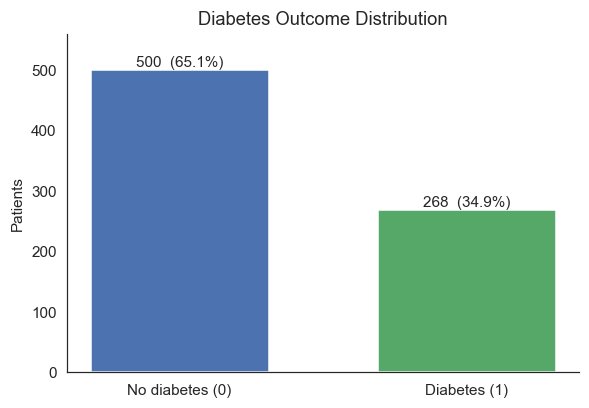

In [7]:
target_counts = df_clean["Outcome"].value_counts().sort_index()
target_share = (target_counts / len(df_clean) * 100).round(1)
labels = ["No diabetes (0)", "Diabetes (1)"]

fig, ax = plt.subplots(figsize=(6, 4))
# Matplotlib bars avoid seaborn-version-specific `legend` arguments.
ax.bar(labels, target_counts.values, color=[PRIMARY, SECONDARY], width=0.62)
for i, (count, share) in enumerate(zip(target_counts, target_share)):
    ax.text(i, count + 6, f"{count}  ({share}%)", ha="center")
ax.set_ylim(0, target_counts.max() * 1.12)
ax.set_ylabel("Patients")
ax.set_title("Diabetes Outcome Distribution")
plt.show()

268 of 768 patients (34.9%) have diabetes. The classes are moderately imbalanced: a model that always predicted "no diabetes" would already be right 65.1% of the time, so accuracy alone is a weak yardstick. I therefore report ROC-AUC, precision, recall and F1 alongside it, and split the data with stratification so that both sets keep the same class ratio.

### Feature Distributions

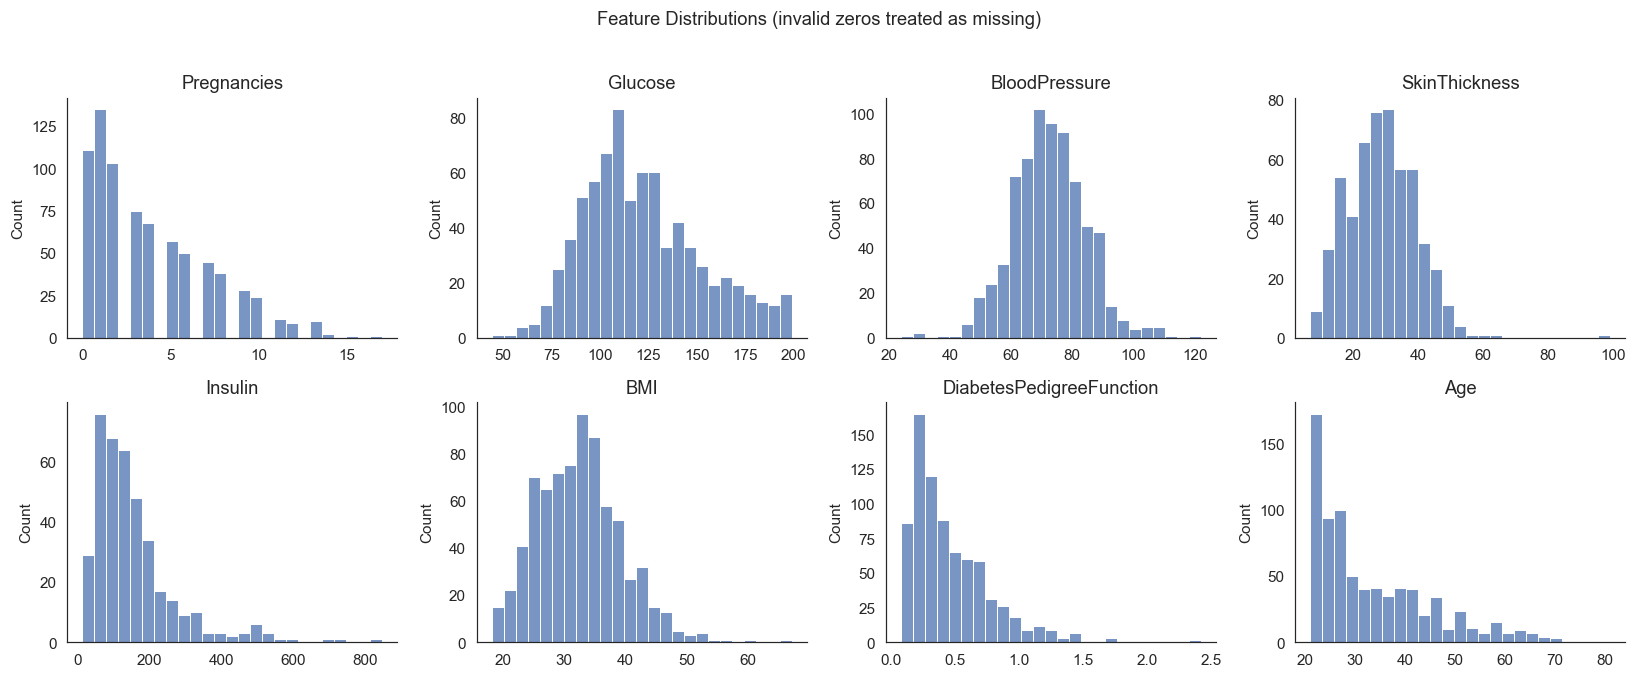

In [8]:
features = df_clean.columns.drop("Outcome")

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df_clean[col].dropna(), bins=25, color=PRIMARY, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Feature Distributions (invalid zeros treated as missing)", y=1.02)
plt.tight_layout()
plt.show()

`Insulin`, `DiabetesPedigreeFunction`, `Age` and `Pregnancies` have noticeable right tails. `BloodPressure` is fairly symmetric, while `Glucose` and `BMI` are both moderately right-skewed. Logistic Regression does not require normally distributed inputs, so I keep the original features and standardize them inside the pipeline.

### Correlation Analysis

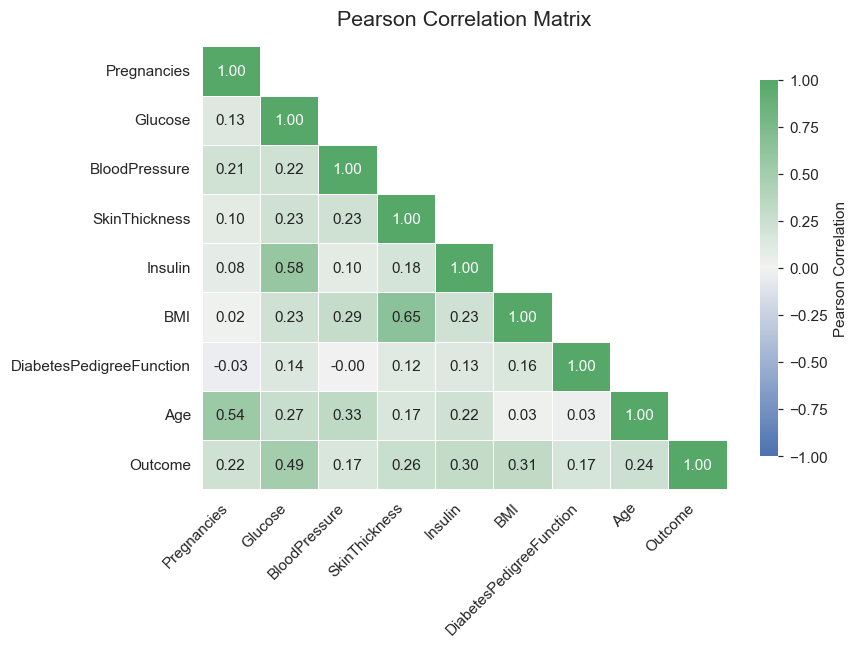

,correlation_with_outcome
Glucose,0.49
BMI,0.31
Insulin,0.30
SkinThickness,0.26
Age,0.24
Pregnancies,0.22
DiabetesPedigreeFunction,0.17
BloodPressure,0.17


In [9]:
# Pearson correlation on the cleaned data (invalid zeros excluded, pairwise complete observations).
corr_matrix = df_clean.corr(method="pearson")

# Mask the upper triangle to avoid showing duplicate information.
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f", cmap=correlation_cmap,
    center=0, vmin=-1, vmax=1, linewidths=0.5, linecolor="white",
    annot_kws={"size": 10}, cbar_kws={"shrink": 0.85, "label": "Pearson Correlation"},
)
plt.title("Pearson Correlation Matrix", fontsize=14, pad=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

corr_matrix["Outcome"].drop("Outcome").sort_values(ascending=False).round(2).to_frame("correlation_with_outcome")

`Glucose` has by far the strongest linear relationship with the outcome (0.49), followed by `BMI` (0.31) and `Insulin` (0.30). The remaining features sit between 0.17 and 0.26. Some predictors also overlap: `BMI` and `SkinThickness` correlate at 0.65, `Glucose` and `Insulin` at 0.58, and `Age` and `Pregnancies` at 0.54. I keep these relationships in mind when interpreting the model coefficients: a feature can be correlated with the outcome but add little once other features are included.

These Pearson correlations use the cleaned data, with invalid zeros treated as missing. Missing pairs are excluded from each calculation, so correlations involving `Insulin` or `SkinThickness` can be based on fewer patients than those involving `Glucose`. I use the heatmap to spot relationships worth investigating, not as proof of causation or a definitive ranking of features.

### Outliers and Class Separation

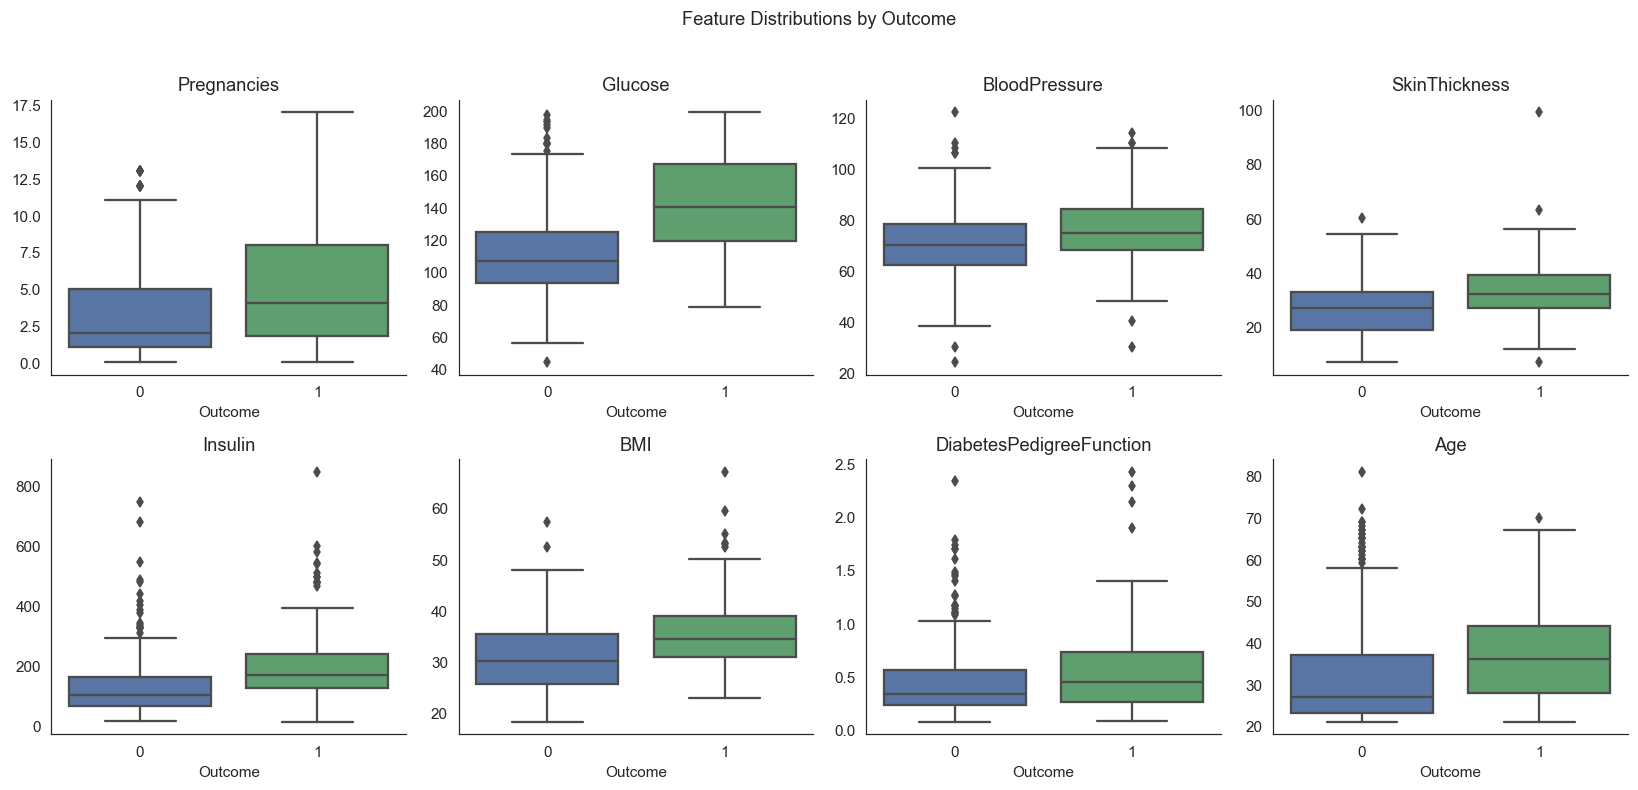

In [10]:

fig, axes = plt.subplots(2, 4, figsize=(15, 7))

outcome_colors = {
    0: PRIMARY,
    1: SECONDARY
}

for ax, col in zip(axes.ravel(), features):
    sns.boxplot(
        data=df_clean,
        x="Outcome",
        y=col,
        hue="Outcome",
        palette=outcome_colors,
        dodge=False,
        ax=ax
    )

    # Remove the redundant legend
    if ax.get_legend() is not None:
        ax.get_legend().remove()

    ax.set_title(col)
    ax.set_xlabel("Outcome")
    ax.set_ylabel("")

fig.suptitle("Feature Distributions by Outcome", y=1.02)
plt.tight_layout()
plt.show()


Patients with diabetes sit clearly higher on `Glucose` and, to a lesser degree, on `BMI`, `Age` and `Pregnancies`. `BloodPressure` and `DiabetesPedigreeFunction` overlap more between the two groups.

Several features show outliers, including very high `Insulin` values and a `SkinThickness` of 99 mm. I kept them because I cannot justify removing them without clinical context. That does not mean they are harmless: `StandardScaler` is sensitive to extreme values, and regularization does not make the model automatically robust to them. I would test how much these observations affect the coefficients and predictions before using the model outside this exercise.

## Modeling Approach

### Train / Test Split

I hold out 20% of the patients as a test set (stratified, fixed seed). The EDA above describes the full dataset, including rows that later end up in the test set, but I do not use those plots to select features or tune the model. In the modeling workflow below, fitting, hyperparameter selection and threshold selection use training data only. I discuss the separate limitation of test-set reuse across earlier project versions when reporting the final results.

In [11]:
X = df_clean.drop(columns="Outcome")
y = df_clean["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

pd.DataFrame(
    {"rows": [len(X_train), len(X_test)],
     "diabetes_rate_%": [round(y_train.mean() * 100, 1), round(y_test.mean() * 100, 1)]},
    index=["train", "test"],
)

,rows,diabetes_rate_%
train,614,34.9
test,154,35.1


614 patients for training and 154 for testing, each with a diabetes rate of about 35%.

### One Pipeline for Everything

Imputation and scaling both learn from data (a median, a mean and a standard deviation), so they must be fitted on training data only. Wrapping them in a scikit-learn `Pipeline` together with the model guarantees this:

1. **Median imputation** fills the missing values.
2. **Standardization** puts all features on a comparable scale.
3. **Logistic Regression** produces the probability of diabetes.

During cross-validation, every fold fits its own imputer and scaler on that fold's training part and only applies them to its validation part. The same object is used at prediction time, so a new patient goes through exactly the same preprocessing.

In [12]:
def build_pipeline(**model_params):
    """Imputation -> scaling -> Logistic Regression, fitted as one object."""
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, **model_params)),
    ])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
baseline = build_pipeline()
baseline

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

### Logistic Regression in Brief

Logistic Regression estimates the probability that an observation belongs to the positive class:

$$
P(y=1 \mid x)=\frac{1}{1+e^{-(\beta_0+\beta_1x_1+\cdots+\beta_px_p)}}
$$

The probability becomes a class label through a decision threshold, conventionally 0.5. Each coefficient describes how a feature moves the odds of the positive class: positive values raise them, negative values lower them.

I chose it because it is interpretable, which is worth a lot in a medical setting, and because it is a strong baseline for tabular data with a mostly linear signal.

## Baseline Model

I start with a default Logistic Regression inside the pipeline and evaluate it with stratified 5-fold cross-validation on the training data.

In [13]:
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1 Score": "f1",
    "ROC-AUC": "roc_auc",
}

cv_raw = cross_validate(baseline, X_train, y_train, cv=cv, scoring=scoring)

cv_baseline = pd.DataFrame({
    "Mean": {name: cv_raw[f"test_{name}"].mean() for name in scoring},
    "Std": {name: cv_raw[f"test_{name}"].std() for name in scoring},
}).round(3)

cv_baseline

,Mean,Std
Accuracy,0.788,0.019
Precision,0.764,0.060
Recall,0.575,0.023
F1 Score,0.655,0.024
ROC-AUC,0.843,0.019


Across five stratified training folds, the baseline has a mean ROC-AUC of 0.843 with a standard deviation of 0.019. That spread describes variation between folds; it is not a 95% confidence interval. Accuracy averages 0.788, but recall is only 0.575 at the default 0.50 threshold. In this exercise, where I want to identify more positive cases, that gives me a reason to examine the decision threshold before trying a more complex algorithm.

## Hyperparameter Tuning

The one setting worth tuning here is `C`, the inverse regularization strength (smaller values mean stronger regularization). `GridSearchCV` tries six values on the same cross-validation folds and scores them with ROC-AUC, which does not depend on a threshold. Because the imputer and scaler are part of the pipeline, they are refitted inside every fold.

In [14]:
# Regularization strength is the one setting worth tuning here (smaller C = stronger regularization).
# The penalty stays at scikit-learn's default (L2).
param_grid = {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]}

grid_search = GridSearchCV(build_pipeline(), param_grid, cv=cv, scoring="roc_auc")
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)

(pd.DataFrame(grid_search.cv_results_)
   [["param_model__C", "mean_test_score", "std_test_score"]]
   .rename(columns={"param_model__C": "C", "mean_test_score": "cv_roc_auc", "std_test_score": "cv_std"})
   .round(4))

Best parameters: {'model__C': 0.1}


,C,cv_roc_auc,cv_std
0,0.001,0.8328,0.0095
1,0.01,0.8404,0.0121
2,0.1,0.8444,0.0160
3,1,0.8435,0.0185
4,10,0.8433,0.0188
5,100,0.8432,0.0188


From `C = 0.1` upward the scores are practically identical, and only the strongest regularization (`C = 0.001`) costs noticeable performance.

### Is Tuning Worth It?

The best setting (`C = 0.1`) raises mean cross-validated ROC-AUC by only about 0.001 over the baseline. The fourth decimal can shift slightly across library versions. Compared with the fold-to-fold standard deviation of about 0.019, this gain is too small to convince me that a different regularization strength is worthwhile. My training-only decision rule requires an improvement of at least 0.005, so I keep the baseline.

I still report the tuning results. Checking a more complex option and deciding not to use it is part of the modeling process.

In [15]:
baseline_auc = cv_raw["test_ROC-AUC"].mean()
tuned_auc = grid_search.best_score_

# Decision rule applied using training CV scores only:
# keep the tuned model only if it improves cross-validated ROC-AUC by at least 0.005.
MIN_GAIN = 0.005
use_tuned = (tuned_auc - baseline_auc) >= MIN_GAIN
final_model = grid_search.best_estimator_ if use_tuned else baseline

print(f"Improvement from tuning: {tuned_auc - baseline_auc:+.4f} ROC-AUC (minimum required: {MIN_GAIN})")
print("Selected model:", "tuned model" if use_tuned else "baseline model")

pd.DataFrame(
    {"CV ROC-AUC": [baseline_auc, tuned_auc]},
    index=["Baseline (C=1)", "Best GridSearch model"],
).round(4)

Improvement from tuning: +0.0009 ROC-AUC (minimum required: 0.005)
Selected model: baseline model


,CV ROC-AUC
Baseline (C=1),0.8435
Best GridSearch model,0.8444


## Choosing the Decision Threshold

Logistic Regression outputs a probability, and the 0.5 cut-off that turns it into a label is a convention, not a rule. The right value depends on the cost of the two kinds of mistake: a missed diabetic patient (false negative) or an unnecessary follow-up test (false positive).

For this portfolio exercise, I assume that missing a positive case matters more than requesting an extra follow-up test. I therefore set a working goal: at least 80% recall on training out-of-fold predictions. Among the tested thresholds that meet it, I choose the highest one to limit false alarms. This is an illustrative decision rule, not a clinically established target.

The threshold is selected on out-of-fold predictions for the training data, where every patient is scored by a model that never saw them. No test labels or test scores are used in this threshold-selection step.

The baseline-versus-tuned choice also uses training CV scores. This is not a fully nested evaluation of every modeling decision, so the out-of-fold numbers should not be treated as an unbiased estimate of the whole selection process. The held-out test set checks the chosen workflow.

In [16]:
# Out-of-fold probabilities: every training row is scored by a model that never saw it.
oof_proba = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

TARGET_RECALL = 0.80   # screening goal: catch at least 80% of diabetic patients

rows = []
for t in np.round(np.arange(0.05, 0.96, 0.01), 2):
    pred = (oof_proba >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_train, pred),
        "Precision": precision_score(y_train, pred, zero_division=0),
        "Recall": recall_score(y_train, pred),
        "F1 Score": f1_score(y_train, pred),
    })
oof_curve = pd.DataFrame(rows)

# Highest threshold (= fewest false alarms) that still reaches the recall target.
chosen_threshold = float(oof_curve.loc[oof_curve["Recall"] >= TARGET_RECALL, "Threshold"].max())

shown = sorted({0.30, 0.40, 0.50, 0.60, chosen_threshold})
print(f"Selected threshold: {chosen_threshold:.2f}")
oof_curve[oof_curve["Threshold"].isin(shown)].round(3).reset_index(drop=True)

Selected threshold: 0.28


,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.28,0.730,0.581,0.804,0.675
1,0.30,0.733,0.588,0.780,0.671
2,0.40,0.782,0.689,0.682,0.685
3,0.50,0.788,0.759,0.575,0.654
4,0.60,0.770,0.766,0.491,0.598


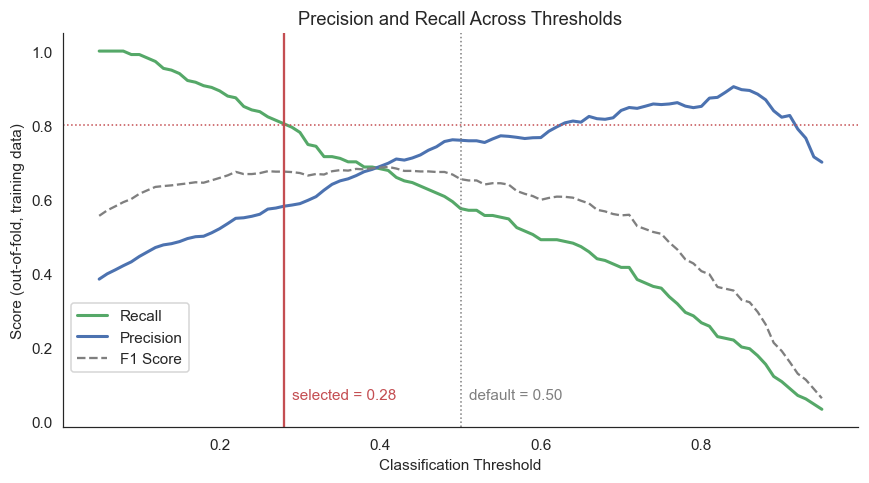

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(oof_curve["Threshold"], oof_curve["Recall"], color=SECONDARY, linewidth=2, label="Recall")
ax.plot(oof_curve["Threshold"], oof_curve["Precision"], color=PRIMARY, linewidth=2, label="Precision")
ax.plot(oof_curve["Threshold"], oof_curve["F1 Score"], color=NEUTRAL, linewidth=1.5, linestyle="--", label="F1 Score")
ax.axhline(TARGET_RECALL, color=ACCENT, linewidth=1, linestyle=":")
ax.axvline(0.5, color=NEUTRAL, linewidth=1, linestyle=":")
ax.axvline(chosen_threshold, color=ACCENT, linewidth=1.5)
ax.text(chosen_threshold + 0.01, 0.06, f"selected = {chosen_threshold:.2f}", color=ACCENT)
ax.text(0.51, 0.06, "default = 0.50", color=NEUTRAL)
ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Score (out-of-fold, training data)")
ax.set_title("Precision and Recall Across Thresholds")
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 0.12))
plt.tight_layout()
plt.show()

Raising the threshold buys precision at the expense of recall, and lowering it does the opposite. At the default 0.50, out-of-fold recall is only 0.57. The highest threshold that reaches the 80% goal is **0.28**, with out-of-fold recall of **0.804** and precision of **0.581**. Recall is only just above the target, so I would not assume this threshold will consistently achieve 80% recall on new populations.

The 80% target is a modeling assumption for this project. In a real setting, the balance between missed cases and extra tests would be set together with clinicians.

## Final Evaluation on the Test Set

I fit the selected model on the full training set and report test performance at both the default threshold and the threshold chosen from training data. No test scores are used to retune the model or choose the threshold in this notebook.

There is one limitation worth being open about: I inspected this same test split while developing earlier versions of the project. So although the current code separates test data from model selection, these results are not fully independent of the entire development history. I would want a genuinely new external dataset before making stronger claims about generalization.

In [18]:
final_model.fit(X_train, y_train)
test_proba = final_model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_proba)


def summarize(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred),
        "Recall": recall_score(y_true, pred),
        "F1 Score": f1_score(y_true, pred),
    }


test_results = pd.DataFrame({
    "Default threshold (0.50)": summarize(y_test, test_proba, 0.50),
    f"Selected threshold ({chosen_threshold:.2f})": summarize(y_test, test_proba, chosen_threshold),
}).T.round(3)

print(f"Test ROC-AUC (threshold-independent): {test_auc:.3f}\n")
test_results

Test ROC-AUC (threshold-independent): 0.813



,Accuracy,Precision,Recall,F1 Score
Default threshold (0.50),0.708,0.600,0.500,0.545
Selected threshold (0.28),0.727,0.577,0.833,0.682


Test ROC-AUC is 0.813, below the cross-validated mean of about 0.843. With only 154 test patients, sampling variation is a plausible explanation; this single split cannot tell me whether the difference is meaningful. The bootstrap intervals below help put the test result in context, but do not capture every source of uncertainty.

Moving from threshold 0.50 to 0.28 lifts recall from 0.50 to 0.83 and F1 from 0.55 to 0.68. Precision falls from 0.60 to 0.58, and accuracy rises from 0.71 to 0.73.

### Classification Report

In [19]:
print(classification_report(
    y_test, (test_proba >= chosen_threshold).astype(int),
    target_names=["No diabetes", "Diabetes"],
))

              precision    recall  f1-score   support

 No diabetes       0.88      0.67      0.76       100
    Diabetes       0.58      0.83      0.68        54

    accuracy                           0.73       154
   macro avg       0.73      0.75      0.72       154
weighted avg       0.77      0.73      0.73       154



The classification report needs a careful read. The 0.88 precision for the “No diabetes” class means that 88% of patients predicted negative are truly negative. In a binary medical setting, this is the negative predictive value (NPV), not specificity.

Specificity is 0.67: of the 100 patients without diabetes in the test set, 67 are correctly predicted negative and 33 are flagged positive. Precision for the positive (“Diabetes”) class is 0.58. The high NPV is useful context, but it depends on the prevalence in this dataset and should not be assumed to transfer to a different population.

### Confusion Matrices

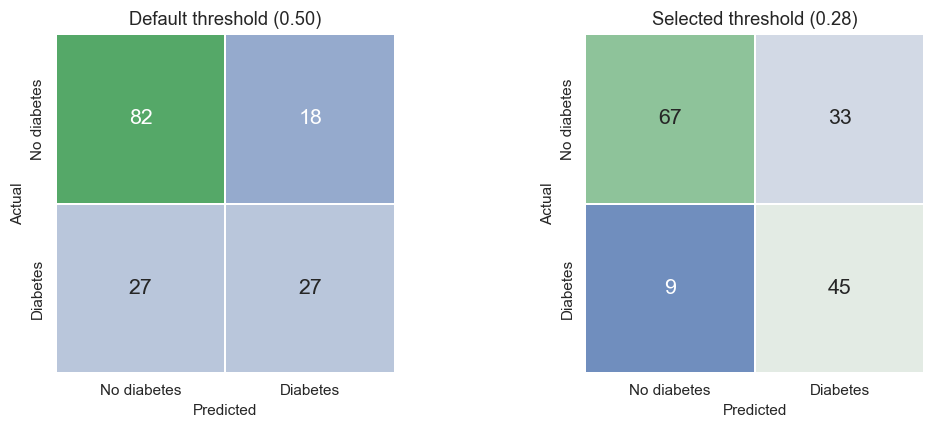

At threshold 0.28 -> TN: 67, FP: 33, FN: 9, TP: 45


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
panels = [(0.50, "Default threshold (0.50)"), (chosen_threshold, f"Selected threshold ({chosen_threshold:.2f})")]

# Use the same count-to-color scale in both panels for a fair comparison.
shared_max = max(
    confusion_matrix(y_test, (test_proba >= t).astype(int)).max()
    for t, _ in panels
)

for ax, (t, title) in zip(axes, panels):
    cm = confusion_matrix(y_test, (test_proba >= t).astype(int))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap=correlation_cmap, vmin=0, vmax=shared_max, cbar=False, square=True,
        linewidths=1, linecolor="white", annot_kws={"size": 14}, ax=ax,
        xticklabels=["No diabetes", "Diabetes"], yticklabels=["No diabetes", "Diabetes"],
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, (test_proba >= chosen_threshold).astype(int)).ravel()
print(f"At threshold {chosen_threshold:.2f} -> TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")

At the selected threshold the model finds 45 of the 54 diabetic patients and misses 9; at 0.50 it would have missed 27. The price is 33 false alarms instead of 18.

Under this hypothetical follow-up rule, the model would flag 78 of 154 test patients (51%); 45 of those 78 are true positive cases.

The blue–green shading represents how many patients are in each cell, not whether the prediction is good or bad. Both matrices use the same count scale, so the numbers and row/column labels, not the color alone, should guide interpretation.

### ROC Curve

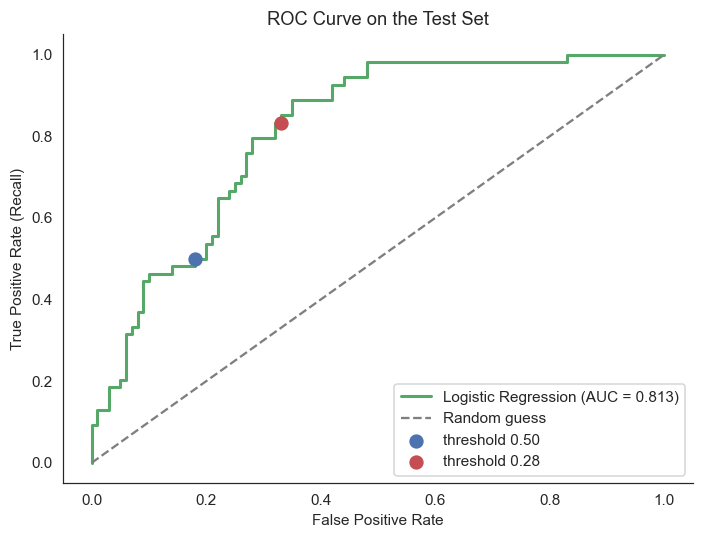

In [21]:
fpr, tpr, _ = roc_curve(y_test, test_proba)
negatives, positives = (y_test == 0).sum(), (y_test == 1).sum()

plt.figure(figsize=(6.5, 5))
plt.plot(fpr, tpr, color=SECONDARY, linewidth=2, label=f"Logistic Regression (AUC = {test_auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color=NEUTRAL, label="Random guess")

for t, color, name in [(0.50, PRIMARY, "threshold 0.50"), (chosen_threshold, ACCENT, f"threshold {chosen_threshold:.2f}")]:
    pred = test_proba >= t
    plt.scatter(((pred) & (y_test == 0)).sum() / negatives, ((pred) & (y_test == 1)).sum() / positives,
                s=70, color=color, zorder=3, label=name)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve on the Test Set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

The two markers show the same model at two operating points. Moving along the curve changes the trade-off between catching cases and raising false alarms, not the model's ability to separate the classes. That ability is summarized by the ROC-AUC of 0.813.

### How Much Should These Numbers Be Trusted?

In [22]:
# With only a few dozen positive cases in the test set, a single number can mislead.
# A bootstrap shows how much these estimates could move with a different sample.
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot = {"ROC-AUC": [], "Recall": [], "Precision": []}

for _ in range(2000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx].min() == y_arr[idx].max():
        continue
    pred = (test_proba[idx] >= chosen_threshold).astype(int)
    boot["ROC-AUC"].append(roc_auc_score(y_arr[idx], test_proba[idx]))
    boot["Recall"].append(recall_score(y_arr[idx], pred))
    boot["Precision"].append(precision_score(y_arr[idx], pred, zero_division=0))

confidence_intervals = pd.DataFrame(
    {name: np.percentile(values, [2.5, 97.5]) for name, values in boot.items()},
    index=["95% CI lower", "95% CI upper"],
).T.round(3)

confidence_intervals

,95% CI lower,95% CI upper
ROC-AUC,0.740,0.873
Recall,0.730,0.929
Precision,0.468,0.684


With only 54 positive cases in the test set, I did not want to present a single score as if it were exact. I drew 2,000 bootstrap samples from the test cases and recalculated the metrics each time. The model and the 0.28 threshold stayed fixed.

The approximate 95% bootstrap percentile intervals are 0.74–0.87 for ROC-AUC, 0.73–0.93 for recall, and 0.47–0.68 for precision. They show sampling uncertainty conditional on this fitted model and threshold; they do not include uncertainty from retraining, choosing a new threshold, or using a different population.

These intervals are fairly wide. Even the lower bound of the bootstrap interval (0.74) is well above the chance-level ROC-AUC of 0.50, suggesting meaningful discrimination on this test set. Still, I would not treat small differences between models or thresholds as reliable without more independent data.

## Model Interpretation

Because the inputs are standardized, I can compare the fitted coefficients on the same scale. Exponentiating a coefficient gives an **odds ratio for a one-standard-deviation increase**, holding the other model features constant. An odds ratio is **not** a probability ratio, and these associations do not establish a causal effect.

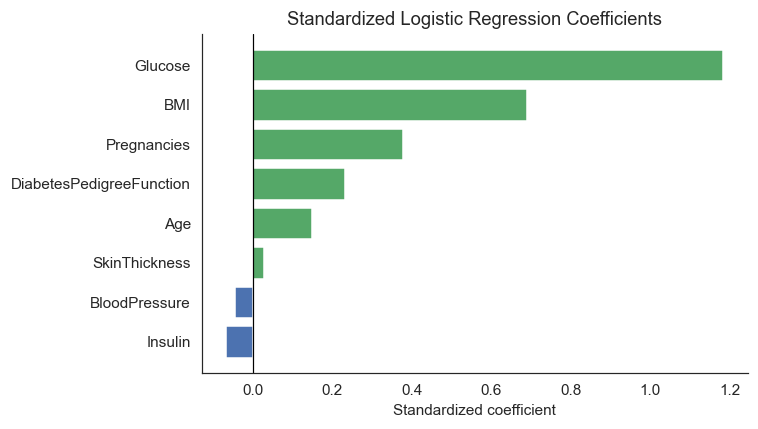

,Feature,Coefficient,Odds ratio (+1 SD)
0,Glucose,1.183,3.263
1,BMI,0.689,1.992
2,Pregnancies,0.377,1.458
3,DiabetesPedigreeFunction,0.233,1.263
4,Age,0.148,1.160
5,SkinThickness,0.028,1.028
6,BloodPressure,-0.044,0.957
7,Insulin,-0.066,0.936


In [23]:
coefficients = (
    pd.DataFrame({
        "Feature": X.columns,
        "Coefficient": final_model.named_steps["model"].coef_[0],
    })
    .assign(**{"Odds ratio (+1 SD)": lambda d: np.exp(d["Coefficient"])})
    .sort_values("Coefficient", ascending=False)
    .round(3)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(7, 4))
bar_colors = [SECONDARY if c > 0 else PRIMARY for c in coefficients["Coefficient"]]
ax.barh(coefficients["Feature"], coefficients["Coefficient"], color=bar_colors)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Standardized coefficient")
ax.set_title("Standardized Logistic Regression Coefficients")
plt.tight_layout()
plt.show()

coefficients

`Glucose` has the largest positive coefficient: a one-standard-deviation increase (about 30 mg/dL), with other features held constant, is associated with roughly 3.3 times the modeled odds of diabetes, not 3.3 times the probability. `BMI` follows (odds ratio of about 2.0 per 6.8 kg/m²), then `Pregnancies`, `DiabetesPedigreeFunction` and `Age`.

`BloodPressure`, `SkinThickness` and `Insulin` have coefficients close to zero. That does not make them medically irrelevant: `Insulin` and `SkinThickness` have substantial imputation (48.7% and 29.6% missing, respectively), and `Insulin` overlaps with `Glucose` (correlation 0.58), while `SkinThickness` overlaps with `BMI` (0.65). Along with the missing measurements, this may help explain why their coefficients are small after the model accounts for other features. These are statistical associations within this dataset, not causal effects.

## Example Prediction

Because the pipeline contains all preprocessing, predicting for a new patient takes a single call on the raw values, missing ones included. The example uses the first patient of the test set.

In [24]:
# The pipeline takes raw, unscaled values (including missing ones) and applies
# the imputation and scaling learned from the training data.
sample = X_test.iloc[[0]]

probability = final_model.predict_proba(sample)[0, 1]
predicted = "Diabetes" if probability >= chosen_threshold else "No diabetes"
actual = "Diabetes" if y_test.iloc[0] == 1 else "No diabetes"

print(f"Predicted probability of diabetes: {probability:.1%}")
print(f"Prediction at threshold {chosen_threshold:.2f}: {predicted}  (actual: {actual})")
sample

Predicted probability of diabetes: 61.0%
Prediction at threshold 0.28: Diabetes  (actual: No diabetes)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
44,7,159.0,64.0,NaN,NaN,27.4,0.294,40


The model estimates a 61.0% probability for this example, above the 0.28 threshold, so it would be flagged for follow-up under the exercise’s decision rule. The recorded outcome is “No diabetes”, making this a false positive. Because I have not checked probability calibration, I treat 61% as an uncalibrated model probability, not a validated estimate of this patient's clinical risk.

## Conclusion

Logistic Regression is a solid baseline for this dataset, with a cross-validated ROC-AUC of 0.843 and 0.813 on the held-out test set.

- **Data quality mattered first.** Five columns hid invalid zeros, up to 48.7% of the rows in `Insulin`. Treating them as missing and imputing inside the pipeline kept the preprocessing free of leakage.
- **Tuning did not justify switching models.** The best `C` gained only about 0.001 ROC-AUC, small compared with the variation between CV folds, so I kept the simpler baseline.
- **Threshold choice changed the trade-off.** Moving from 0.50 to 0.28 raised test recall from 0.50 to 0.83, but also increased false alarms (precision at 0.28: 0.58).
- **Glucose and BMI have the largest positive coefficients** in this fitted model. That is a statistical finding here, not proof that changing either measurement would cause the predicted outcome to change.

The main lesson is that choosing a decision rule for the objective mattered more for recall than adding model complexity. The extra cases found came with more false alarms.

### Limitations

- **Small dataset.** With 768 patients and only 54 positive cases in the test set, the confidence intervals are wide.
- **Narrow population.** All patients are women of at least 21 years from one population, so the results may not transfer elsewhere.
- **Substantial missingness.** Invalid zeros affect 48.7% of `Insulin` and 29.6% of `SkinThickness`. Median imputation is a reasonable baseline, but it can hide information in the missingness pattern.
- **Assumed costs and threshold stability.** The 80% recall target is a project assumption, not a clinical requirement. The selected training recall is only just above that target.
- **Test-set reuse across development.** Although the current code keeps the test set out of model and threshold selection, earlier project iterations were inspected using this same test set. External validation would give a more independent assessment.
- **Uncalibrated probabilities and no clinical validation.** The predicted probabilities have not been calibrated or tested in a clinical workflow. This is a learning and portfolio project, not a diagnostic tool.

### Next Steps

- Compare tree-based models (Random Forest, gradient boosting) using the same pipeline and cross-validation. Logistic Regression was chosen here for interpretability, but a complete workflow would benchmark other algorithms.
- Try `class_weight="balanced"` and probability calibration.
- Explore feature engineering: glucose and BMI bands, interaction terms, and missing-value indicators for `Insulin` and `SkinThickness`.
- Use repeated cross-validation for more stable estimates, then evaluate the finalized workflow on a genuinely independent dataset if one becomes available.
- Check sensitivity to extreme measurements, for example by comparing standard and robust scaling on training folds.

## What I Learned

- **An evaluation is only as trustworthy as its setup.** Imputation and scaling need to be fitted within training folds, and the classification threshold should be selected without consulting the held-out test results. A single pipeline and training-only out-of-fold predictions make these choices traceable.
- **The metric should follow the goal.** For this exercise, I put more weight on finding positive cases than on accuracy alone, even though that means more false alarms.
- **More tuning is not always the answer.** The threshold had far more impact on recall than changing regularization strength.
- **Uncertainty belongs in the report.** On a small test set, bootstrap intervals put the headline scores in context, but they do not replace external validation or measure every source of uncertainty.

## Project Links

### GitHub Repository
[GitHub project page](https://github.com/anahitapouladi/diabetes-prediction-logistic-regression)

### Kaggle Notebook
[Kaggle project page](https://www.kaggle.com/code/anahitapouladi/diabetes-prediction-logistic-regression)

**Dataset documentation:** [Pima Indians Diabetes Database (Kaggle / UCI Machine Learning)](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database)

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, scikit-learn (`Pipeline`, `SimpleImputer`, `StandardScaler`, `GridSearchCV`, `cross_val_predict`)